# Predicting port congestion and vessel waiting delays

At arrival, estimate whether a vessel will wait **more than six hours** before berthing, return an estimated probability, and explain the main factors.

**All training and evaluation data are synthetic.** Ports and dates are fictional. Read [PROBLEM_DEFINITION.md](PROBLEM_DEFINITION.md) and [DATA_DICTIONARY.md](DATA_DICTIONARY.md) for assumptions.


## 1. Environment and paths

Launch Jupyter from this directory and choose the project kernel. The notebook and command-line tools share one implementation. Seed 42 makes the simulated data reproducible.


In [1]:
import json
import sys
from importlib.metadata import version
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display
from port_delay import RAW_INPUTS, predict_one, run, simulate

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "PROBLEM_DEFINITION.md").is_file():
    raise FileNotFoundError("Launch Jupyter from the project folder.")
if sys.prefix == sys.base_prefix:
    raise RuntimeError("Select the project virtual environment kernel.")
print(f"Python {sys.version.split()[0]} | {sys.executable}")
packages = ["numpy", "pandas", "scikit-learn", "matplotlib", "joblib", "notebook", "ipykernel"]
display(pd.DataFrame({"package": packages, "version": [version(p) for p in packages]}))


Python 3.12.7 | /Users/gaurav/Desktop/port-delay-prediction/.venv/bin/python


,package,version
0,numpy,2.5.4
1,pandas,3.0.6
2,scikit-learn,1.9.1
3,matplotlib,3.11.2
4,joblib,1.6.0
5,notebook,7.6.3
6,ipykernel,7.4.0


## 2. Data and ground truth

One row represents one vessel visit. A first-come-first-served simulator tracks when each berth becomes free. Berthing begins at the later of arrival and earliest berth availability. The target is a wait strictly greater than six hours; equality is not delayed.

The simulator uses three ports (3, 5, and 7 berths), daytime arrival peaks, variable service durations, 12-hour weather episodes, and occasional unobserved disruptions. It runs 150 warmup visits before exporting 500 records. Weather and historical-service observations are independently removed with probability 3%. All features reflect information available at arrival.


In [2]:
preview = simulate()
print(f"{len(preview)} visits, {preview.is_delayed.sum()} delayed ({preview.is_delayed.mean():.1%})")
display(preview.head())
display(preview.groupby("port_id").agg(visits=("visit_id", "size"), delay_rate=("is_delayed", "mean"), mean_wait_hours=("waiting_hours", "mean")))
display(preview[RAW_INPUTS].isna().sum().rename("missing_count").to_frame())


500 visits, 98 delayed (19.6%)


,visit_id,port_id,arrival_time,berth_start_time,service_end_time,label_available_time,queue_length,operational_berths,busy_berths,arrivals_past_6h,weather_severity,past_avg_service_hours,waiting_hours,is_delayed
0,VISIT_0001,PORT_C,2025-01-05 20:30:10.640229084+00:00,2025-01-05 20:30:10.640229084+00:00,2025-01-06 07:12:28.209666585+00:00,2025-01-05 20:30:10.640229084+00:00,0,7,4,2,1.0,9.542230,0.000000,0
1,VISIT_0002,PORT_C,2025-01-05 20:44:26.768071906+00:00,2025-01-05 20:44:26.768071906+00:00,2025-01-06 06:28:56.626017909+00:00,2025-01-05 20:44:26.768071906+00:00,0,7,5,3,1.0,9.542230,0.000000,0
2,VISIT_0003,PORT_A,2025-01-05 21:45:43.243820776+00:00,2025-01-05 21:45:43.243820776+00:00,2025-01-06 03:01:05.839555979+00:00,2025-01-05 21:45:43.243820776+00:00,0,3,0,0,0.0,8.461842,0.000000,0
3,VISIT_0004,PORT_C,2025-01-05 21:55:58.833978758+00:00,2025-01-05 21:55:58.833978758+00:00,2025-01-06 17:45:24.380276083+00:00,2025-01-05 21:55:58.833978758+00:00,0,7,6,4,1.0,9.542230,0.000000,0
4,VISIT_0005,PORT_C,2025-01-05 22:36:59.962325950+00:00,2025-01-05 23:14:41.332324308+00:00,2025-01-06 07:35:40.742753074+00:00,2025-01-05 23:14:41.332324308+00:00,0,7,7,5,1.0,9.542230,0.628158,0


,visits,delay_rate,mean_wait_hours
port_id,,,
PORT_A,111,0.621622,15.484671
PORT_B,154,0.097403,2.028029
PORT_C,235,0.059574,1.898854


,missing_count
queue_length,0
operational_berths,0
busy_berths,0
arrivals_past_6h,0
weather_severity,14
past_avg_service_hours,15


## 3. Fit and evaluate in chronological order

Nominal partitions are 350 earlier arrivals for training, 50 for validation, and the latest 100 for testing. Excluding unresolved labels at each cutoff leaves 348/47/100 usable visits. Imputation and scaling learn from training only.

Inputs are queue per berth, berth utilization, recent arrivals per berth, observed weather, and historical completed service time. The baseline predicts the training class prior. Select logistic-regression C from 0.1, 1, and 10 by validation Brier score. Keep the alert threshold fixed at 0.5. Test outcomes do not select the model, and the saved model is not refitted on test visits.

This cell recreates the synthetic CSV, fitted model, metrics, examples, and charts.


In [3]:
experiment = run(PROJECT_ROOT)
display(experiment["metrics"].round(4))
display(pd.DataFrame([experiment["summary"]["split"]]))
display(pd.read_csv(PROJECT_ROOT / "results/validation_candidates.csv").round(4))


                  model      split   n  accuracy  precision  recall     f1  roc_auc  brier
training_prior_baseline validation  47    0.8511     0.0000  0.0000 0.0000   0.5000 0.1320
training_prior_baseline       test 100    0.8700     0.0000  0.0000 0.0000   0.5000 0.1214
    logistic_regression validation  47    0.9574     1.0000  0.7143 0.8333   0.9929 0.0294
    logistic_regression       test 100    0.9000     0.6667  0.4615 0.5455   0.7701 0.1006
{
  "train": 348,
  "validation": 47,
  "test": 100,
  "train_unresolved_excluded": 2,
  "validation_unresolved_excluded": 3,
  "validation_start": "2025-01-16T17:46:02.063294346+00:00",
  "test_start": "2025-01-18T06:03:26.558130211+00:00"
}


,model,split,n,accuracy,precision,recall,f1,roc_auc,brier
0,training_prior_baseline,validation,47,0.8511,0.0000,0.0000,0.0000,0.5000,0.1320
1,training_prior_baseline,test,100,0.8700,0.0000,0.0000,0.0000,0.5000,0.1214
2,logistic_regression,validation,47,0.9574,1.0000,0.7143,0.8333,0.9929,0.0294
3,logistic_regression,test,100,0.9000,0.6667,0.4615,0.5455,0.7701,0.1006


,train,validation,test,train_unresolved_excluded,validation_unresolved_excluded,validation_start,test_start
0,348,47,100,2,3,2025-01-16T17:46:02.063294346+00:00,2025-01-18T06:03:26.558130211+00:00


,C,accuracy,precision,recall,f1,roc_auc,brier
0,10.0,0.9574,1.0,0.7143,0.8333,0.9929,0.0294
1,1.0,0.9149,1.0,0.4286,0.6000,0.9893,0.0601
2,0.1,0.8511,0.0,0.0000,0.0000,0.9429,0.0957


## 4. Inspect data patterns and held-out performance

Precision measures correct alerts; recall measures caught delays. F1 balances both. ROC-AUC measures ranking, and lower Brier score indicates better overall probability predictions.

The held-out model catches **6 of 13 delays**, misses 7, and raises 3 false alarms: accuracy 90%, precision 66.7%, recall 46.2%, F1 0.545, ROC-AUC 0.770. The no-delay baseline achieves 87% accuracy and catches no delays. Weaker test performance than validation is a limitation.


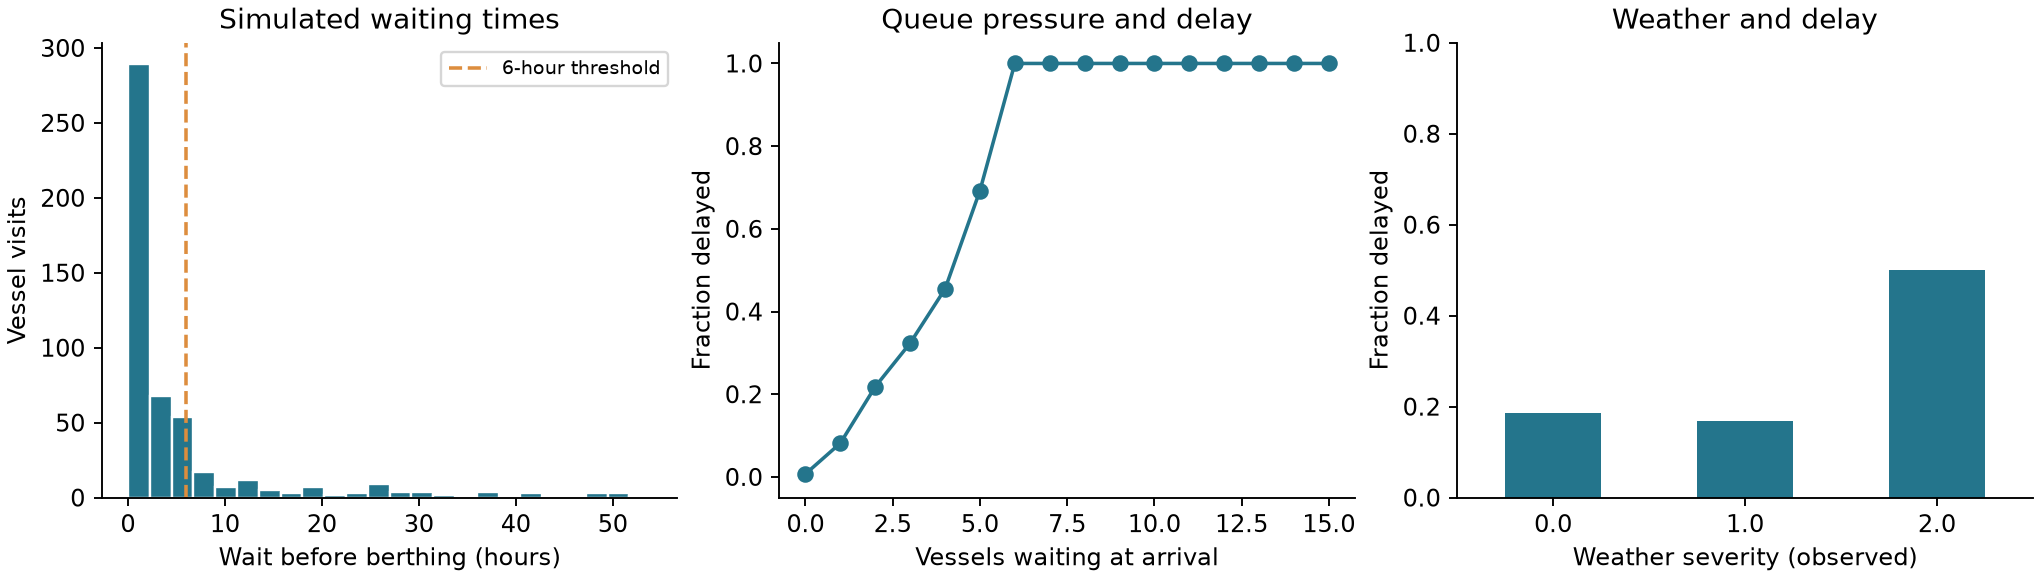

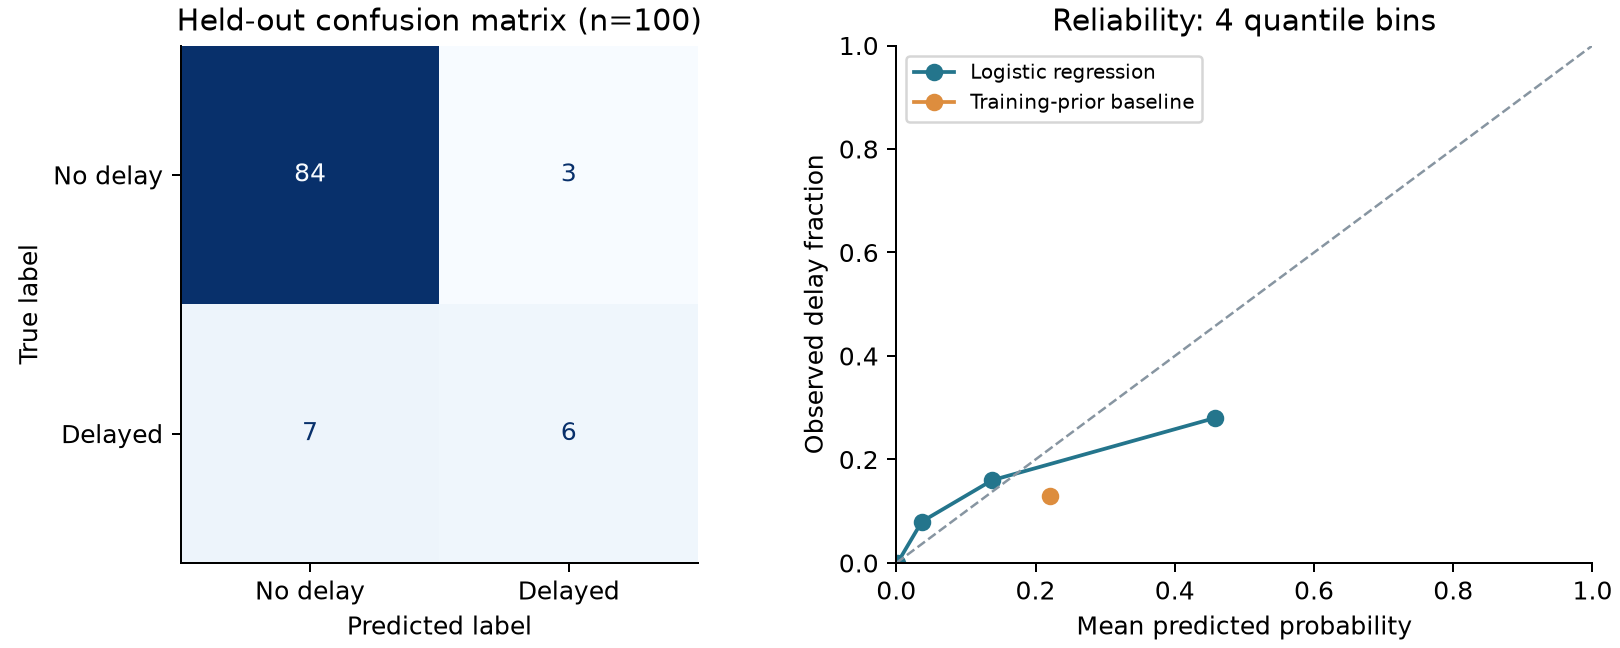

,bin,count,mean_probability,observed_delay_fraction
0,"(-0.00099333, 0.00599]",25,0.0016,0.00
1,"(0.00599, 0.0706]",25,0.0368,0.08
2,"(0.0706, 0.247]",25,0.1379,0.16
3,"(0.247, 0.741]",25,0.4572,0.28


In [4]:
display(Image(filename=str(PROJECT_ROOT / "results/data_overview.png")))
display(Image(filename=str(PROJECT_ROOT / "results/evaluation.png")))
display(pd.read_csv(PROJECT_ROOT / "results/calibration_bins.csv").round(4))


## 5. Probability, confidence, and explanations

Delay probability is the estimated chance of a wait exceeding six hours. Confidence is the probability assigned to the selected outcome: p for delayed and 1-p otherwise. It is not an independent reliability estimate or measured accuracy.

Four quantile bins compare estimated probabilities with observed delay fractions. Only 100 test visits and 13 positive outcomes give limited reliability evidence. Brier score alone does not isolate calibration. No extra calibrator was fitted to the small validation set.

Each logistic-regression contribution equals coefficient times standardized feature. Contributions plus the intercept reconstruct log-odds exactly. Positive terms increase model risk relative to its training-mean reference; negative terms decrease it. These are model associations, not causal effects or percentage-point probability changes.


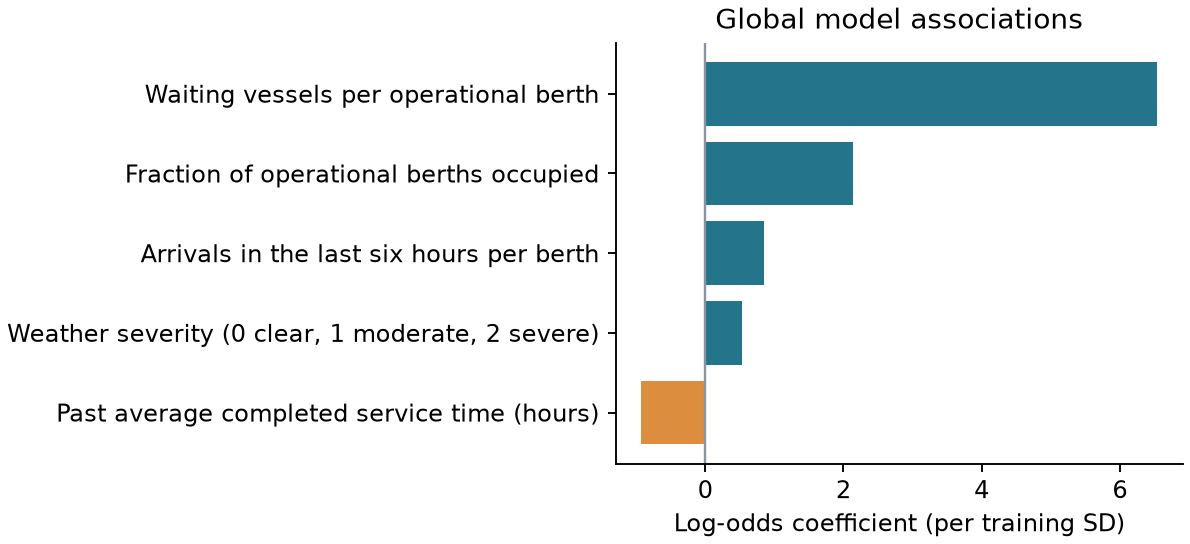

low_risk: no_delay_over_6_hours | probability 0.001% | confidence 99.999%
Illustration from held-out visit VISIT_0432; selecting it did not tune the model.


,description,value,imputed,effect,contribution_log_odds
0,Fraction of operational berths occupied,0.000000,False,decreases delay risk,-5.774913
1,Waiting vessels per operational berth,0.000000,False,decreases delay risk,-3.269856
2,Past average completed service time (hours),8.784789,False,increases delay risk,0.986619


Maintain the current plan and continue monitoring arrival conditions.
high_risk: delay_over_6_hours | probability 74.063% | confidence 74.063%
Illustration from held-out visit VISIT_0469; selecting it did not tune the model.


,description,value,imputed,effect,contribution_log_odds
0,Fraction of operational berths occupied,1.000000,False,increases delay risk,1.701272
1,Waiting vessels per operational berth,0.800000,False,increases delay risk,1.343960
2,Past average completed service time (hours),8.728734,False,increases delay risk,1.092655


Review berth scheduling and notify downstream planners of potential disruption.


In [5]:
display(Image(filename=str(PROJECT_ROOT / "results/feature_coefficients.png")))
for name, example in experiment["examples"].items():
    result = example["result"]
    print(f"{name}: {result['prediction']} | probability {result['delay_probability']:.3%} | confidence {result['confidence_score']:.3%}")
    print(f"Illustration from held-out visit {example['source_visit']}; selecting it did not tune the model.")
    display(pd.DataFrame(result["main_factors"])[["description", "value", "imputed", "effect", "contribution_log_odds"]])
    print(result["suggested_action"])


## 6. Try a new arrival

Edit the observed conditions below. Counts must be nonnegative integers; capacity must be positive, and occupied berths cannot exceed it. Weather and historical service time may be null. Training medians then fill missing values, and the output flags them.


In [6]:
arrival = {
    "queue_length": 2,
    "operational_berths": 5,
    "busy_berths": 5,
    "arrivals_past_6h": 4,
    "weather_severity": 1,
    "past_avg_service_hours": 9.5,
}
result = predict_one(experiment["model"], arrival)
print(json.dumps(result, indent=2))


{
  "prediction": "no_delay_over_6_hours",
  "delay_probability": 0.1952375642570907,
  "confidence_score": 0.8047624357429093,
  "confidence_definition": "Estimated probability of the selected outcome, not measured accuracy.",
  "decision_threshold": 0.5,
  "main_factors": [
    {
      "feature": "berth_utilization",
      "description": "Fraction of operational berths occupied",
      "value": 1.0,
      "imputed": false,
      "contribution_log_odds": 1.7012720389754163,
      "effect": "increases delay risk"
    },
    {
      "feature": "queue_per_berth",
      "description": "Waiting vessels per operational berth",
      "value": 0.4,
      "imputed": false,
      "contribution_log_odds": -0.9629478945651538,
      "effect": "decreases delay risk"
    },
    {
      "feature": "weather_severity",
      "description": "Weather severity (0 clear, 1 moderate, 2 severe)",
      "value": 1.0,
      "imputed": false,
      "contribution_log_odds": 0.5885830753068393,
      "effect": "

## 7. Verify and prepare the local submission

Tests check reproducibility, target arithmetic, arrival snapshots using only prior visits, chronological label availability, invalid inputs, missing-data handling, saved-model predictions, and reconstruction of probabilities from explanations.


In [7]:
import subprocess
check = subprocess.run([sys.executable, "-m", "unittest", "discover", "-s", "tests", "-v"], cwd=PROJECT_ROOT, text=True, capture_output=True, check=True)
print(check.stdout + check.stderr)


test_input_validation_and_outcome_independence (test_port_delay.PortDelayTests.test_input_validation_and_outcome_independence) ... ok
test_labels_resolved_before_training_cutoffs (test_port_delay.PortDelayTests.test_labels_resolved_before_training_cutoffs) ... ok
test_missing_observations_are_imputed_and_flagged (test_port_delay.PortDelayTests.test_missing_observations_are_imputed_and_flagged) ... ok
test_reproducible_simulation_and_ground_truth (test_port_delay.PortDelayTests.test_reproducible_simulation_and_ground_truth) ... ok
test_saved_model_explanations_and_reload (test_port_delay.PortDelayTests.test_saved_model_explanations_and_reload) ... ok
test_snapshots_only_use_prior_visits (test_port_delay.PortDelayTests.test_snapshots_only_use_prior_visits) ... ok

----------------------------------------------------------------------
Ran 6 tests in 0.129s

OK



## Deliverables and limitations

The three-page technical report is available at **output/pdf/port_congestion_report.pdf**. README.md documents environment setup, training, and CLI predictions. Everything remains local.

This small synthetic study has fixed berth counts, simplified operations, three previously seen fictional ports, and a short time window. It does not establish real-port performance, seasonal effects, generalization to new ports, or the causal benefit of operational changes. If missed delays are costly, choose a new alert policy on future validation periods and assess subsequent model changes on a fresh forward holdout.
